# 08 — Modèle mixte par-km + décomposition de variance

**Question scientifique** : à l'échelle du kilomètre, quelle part de la pace instantanée est expliquée par :
- des features **au niveau sortie** (T°, forme récente, contexte social, ensoleillement) 
- des features **au niveau intra-sortie** (avancement, pente locale),
- un effet aléatoire **par sortie** qui capture "la forme du jour" non observée (sommeil, humeur, nutrition, etc.),
- et le **bruit résiduel km à km** ?

**Approche** : modèle mixte linéaire `pace_km ~ features + (1 | activity_id)` sur la table `activities_km`, puis décomposition de variance en 4 blocs.

**Prolongement du notebook 07** : on reprend les deux découvertes majeures (interaction thermo-solaire T × sun et flag course accompagnée is_accompagne) et on les valide en structure hiérarchique. Objectif : voir si la "forme du jour résiduelle" (50 % de la variance dans la version précédente du modèle) chute une fois ces features ajoutées.

## Setup et chargement

In [15]:
from dotenv import load_dotenv
load_dotenv()

import os
import re
import sys
sys.path.append("../streamlit_app")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
from sqlalchemy import create_engine

sns.set_theme(style="whitegrid", context="talk")
plt.rcParams["figure.figsize"] = (10, 5)

FIG_DIR = "../docs/figures"
os.makedirs(FIG_DIR, exist_ok=True)

engine = create_engine(os.environ["DATABASE_URL"].replace("postgres://", "postgresql://", 1))
df_km  = pd.read_sql("SELECT * FROM activities_km", engine)
df_act = pd.read_sql("SELECT * FROM activities_enriched", engine)

print(f"df_km  : {len(df_km)} lignes ({df_km['activity_id'].nunique()} sorties)")
print(f"df_act : {len(df_act)} sorties, {len(df_act.columns)} colonnes")

df_km  : 808 lignes (134 sorties)
df_act : 134 sorties, 46 colonnes


## Enrichissement des features sortie (sun_load, T_x_sun, is_accompagne)

On reproduit les features dérivées du notebook 07 (élévation solaire géométrique et flag course accompagnée) directement sur `df_act`, avant de merger sur les lignes km. Logique identique à celle du 07 pour cohérence.

In [16]:
# --- Élévation solaire géométrique ---
LAT_COMPIEGNE = 49.4179
LON_COMPIEGNE = 2.8260

def solar_elevation(dt_utc, lat_deg=LAT_COMPIEGNE, lon_deg=LON_COMPIEGNE):
    dt_utc = pd.to_datetime(dt_utc, utc=True)
    doy = dt_utc.timetuple().tm_yday
    h = dt_utc.hour + dt_utc.minute / 60
    gamma = 2 * np.pi / 365 * (doy - 1 + (h - 12) / 24)
    decl = (0.006918 - 0.399912 * np.cos(gamma) + 0.070257 * np.sin(gamma)
            - 0.006758 * np.cos(2 * gamma) + 0.000907 * np.sin(2 * gamma))
    solar_hour = h + lon_deg / 15
    hour_angle = np.radians((solar_hour - 12) * 15)
    lat_rad = np.radians(lat_deg)
    sin_elev = (np.sin(lat_rad) * np.sin(decl)
                + np.cos(lat_rad) * np.cos(decl) * np.cos(hour_angle))
    return np.degrees(np.arcsin(np.clip(sin_elev, -1, 1)))

df_act["solar_elev"] = df_act["start_date_local"].apply(solar_elevation)
df_act["sun_load"] = df_act["solar_elev"].clip(lower=0)
df_act["T_x_sun"] = df_act["weather_temperature"] * df_act["sun_load"] / 100

# --- Flag course accompagnée (règle hybride regex + exclusion vélo + seuil pace >= 6) ---
ACCOMPAGNE_PATTERNS = [
    r"\bavec\b", r"\bparents?\b", r"\bgrands?[- ]parents?\b",
    r"\bmaman\b|\bpapa\b", r"\bmadre\b|\bpadre\b",
    r"\byanis\b", r"\bmaxime\b", r"\bromance\b",
    r"\blana\b|#LanaRun",
    r"\b(?:p['’]?tit|petit)\s+fr[èe]re\b",
    r"\bfr[èe]re\b|\bsoeur\b|\bsœur\b",
]
PATTERN_RE = re.compile("|".join(ACCOMPAGNE_PATTERNS), flags=re.IGNORECASE)
EXCLUDE_PATTERNS = [r"\bau\s+v[ée]lo\b", r"\b[àa]\s+v[ée]lo\b",
                    r"\bcycliste\b", r"\bvtt\b"]
EXCLUDE_RE = re.compile("|".join(EXCLUDE_PATTERNS), flags=re.IGNORECASE)
SEUIL_PACE_ACCOMPAGNE = 6.0

df_act["desc"] = df_act["description"].fillna("")
df_act["has_hint"] = df_act["desc"].str.contains(PATTERN_RE)
df_act["has_exclude"] = df_act["desc"].str.contains(EXCLUDE_RE)
df_act["is_accompagne"] = (
    df_act["has_hint"] & ~df_act["has_exclude"]
    & (df_act["pace_min_km"] >= SEUIL_PACE_ACCOMPAGNE)
).astype(int)

print(f"Flaggées accompagnées : {df_act['is_accompagne'].sum()}/{len(df_act)}")

Flaggées accompagnées : 9/134


## Merge features sortie + lignes km

Chaque ligne de `df_km` est enrichie des features de sa sortie parente, pour permettre le fit du modèle mixte.

In [17]:
act_cols = ["id", "distance_km", "weather_temperature", "weather_humidity",
            "pace_last_5_mean", "pace_min_km", "start_date_local",
            "sun_load", "T_x_sun", "is_accompagne"]

df = df_km.merge(df_act[act_cols], left_on="activity_id", right_on="id")
df = df.rename(columns={
    "pace_min_per_km": "pace_km",       # y du modèle (pace du km courant)
    "pace_min_km": "pace_sortie",       # pace moyenne sortie (pas prédicteur)
    "km_distance_m": "km_dist_m",
    "distance_km": "dist_totale_km",
})

print(f"Total merge : {len(df)} lignes km")
print(df[["activity_id", "km_index", "pace_km", "fraction_completed",
          "avg_grade_pct", "dist_totale_km", "weather_temperature",
          "sun_load", "T_x_sun", "is_accompagne", "pace_last_5_mean"]].head())

Total merge : 808 lignes km
   activity_id  km_index   pace_km  fraction_completed  avg_grade_pct  \
0  11346532154         1  4.611529            0.333333       0.861244   
1  11346532154         2  4.293208            0.666667      -0.257684   
2  11346532154         3  4.161538            1.000000      -0.957047   
3  11351598892         1  4.427736            0.250000      -0.863705   
4  11351598892         2  4.467423            0.500000       0.271331   

   dist_totale_km  weather_temperature   sun_load   T_x_sun  is_accompagne  \
0          2.5716                 16.4   8.515206  1.396494              0   
1          2.5716                 16.4   8.515206  1.396494              0   
2          2.5716                 16.4   8.515206  1.396494              0   
3          3.3113                 16.9  57.000921  9.633156              0   
4          3.3113                 16.9  57.000921  9.633156              0   

   pace_last_5_mean  
0               NaN  
1               NaN 

## Filtres de modélisation

- Km complets uniquement (`is_partial = False`)
- Pace ∈ [3, 10] min/km (plausibilité)
- Distance totale sortie ∈ [1, 30[ km
- `pace_last_5_mean` disponible
- Au moins 3 km exploitables par sortie (pour que l'effet aléatoire ait un sens)

In [18]:
mask = (
    (~df["is_partial"])
    & (df["pace_km"].between(3, 10))
    & (df["dist_totale_km"] >= 1)
    & (df["dist_totale_km"] < 30)
    & (df["pace_last_5_mean"].notna())
)
dfm = df[mask].copy()
counts = dfm.groupby("activity_id")["km_index"].transform("count")
dfm = dfm[counts >= 3]

print(f"n lignes km après filtres : {len(dfm)}")
print(f"n sorties                : {dfm['activity_id'].nunique()}")
print(f"  dont accompagnées      : {dfm.drop_duplicates('activity_id')['is_accompagne'].sum()}")
print(f"\nStats pace par km :")
print(dfm['pace_km'].describe().round(3))

n lignes km après filtres : 592
n sorties                : 91
  dont accompagnées      : 7

Stats pace par km :
count    592.000
mean       5.046
std        0.628
min        3.576
25%        4.590
50%        5.011
75%        5.439
max        6.978
Name: pace_km, dtype: float64


## 1. Modèle null — décomposition initiale de la variance

Modèle `pace_km ~ 1 + (1 | activity_id)`. L'ICC (Intra-Class Correlation) répond à la question **"combien de la variance totale vient du fait que les kms d'une même sortie se ressemblent, par opposition à la variation km à km au sein d'une sortie"**.

C'est le benchmark à battre : plus l'ICC est élevé, plus il y a de signal à expliquer au niveau sortie.

In [19]:
m_null = smf.mixedlm("pace_km ~ 1", data=dfm, groups=dfm["activity_id"]).fit(method="lbfgs")
print(m_null.summary())

var_between_null = float(m_null.cov_re.iloc[0, 0])
var_within_null = float(m_null.scale)
icc_null = var_between_null / (var_between_null + var_within_null)

print(f"\n=== Décomposition initiale ===")
print(f"Variance between (entre sorties) : {var_between_null:.4f}  →  σ = {np.sqrt(var_between_null)*60:.1f} s/km")
print(f"Variance within  (intra-sortie)  : {var_within_null:.4f}  →  σ = {np.sqrt(var_within_null)*60:.1f} s/km")
print(f"ICC = {icc_null:.3f}  →  {icc_null*100:.1f} % de la variance totale est au niveau sortie")

         Mixed Linear Model Regression Results
Model:            MixedLM Dependent Variable: pace_km  
No. Observations: 592     Method:             REML     
No. Groups:       91      Scale:              0.1226   
Min. group size:  3       Log-Likelihood:     -342.3144
Max. group size:  25      Converged:          Yes      
Mean group size:  6.5                                  
-------------------------------------------------------
              Coef. Std.Err.   z    P>|z| [0.025 0.975]
-------------------------------------------------------
Intercept     4.947    0.059 84.189 0.000  4.832  5.062
Group Var     0.291    0.146                           


=== Décomposition initiale ===
Variance between (entre sorties) : 0.2906  →  σ = 32.3 s/km
Variance within  (intra-sortie)  : 0.1226  →  σ = 21.0 s/km
ICC = 0.703  →  70.3 % de la variance totale est au niveau sortie


## 2. Modèle baseline — contexte sortie + avancement + pente

On commence par la structure du notebook 07 adaptée au par-km :
- Météo brute : T° + T²
- Effort sortie : distance totale
- Forme récente : pace_last_5_mean
- Avancement intra-sortie : fraction_completed (0 au début, 1 à la fin)
- Pente locale du km : avg_grade_pct

Note : on ne met pas `elev_per_km` (niveau sortie) parce que `avg_grade_pct` (niveau km) le capture mieux. On ne met pas non plus `weather_humidity` (non significatif en 07).

In [20]:
FORMULA_BASE = (
    "pace_km ~ weather_temperature + I(weather_temperature**2) "
    "+ dist_totale_km + pace_last_5_mean "
    "+ fraction_completed + avg_grade_pct"
)
m_base = smf.mixedlm(FORMULA_BASE, data=dfm, groups=dfm["activity_id"]).fit(method="lbfgs")
print(m_base.summary())

var_between_base = float(m_base.cov_re.iloc[0, 0])
var_within_base  = float(m_base.scale)
icc_base = var_between_base / (var_between_base + var_within_base)

print(f"\n=== Variance après baseline ===")
print(f"Variance between résiduelle : {var_between_base:.4f}")
print(f"Variance within résiduelle  : {var_within_base:.4f}")
print(f"ICC résiduel = {icc_base:.3f}")

r2_between_base = 1 - var_between_base / var_between_null
r2_within_base  = 1 - var_within_base  / var_within_null
print(f"\n→ Les features baseline expliquent {r2_between_base*100:.1f} % de la variance BETWEEN")
print(f"→ Les features baseline expliquent {r2_within_base*100:.1f} % de la variance WITHIN")

                Mixed Linear Model Regression Results
Model:                 MixedLM      Dependent Variable:      pace_km  
No. Observations:      592          Method:                  REML     
No. Groups:            91           Scale:                   0.1004   
Min. group size:       3            Log-Likelihood:          -294.4440
Max. group size:       25           Converged:               Yes      
Mean group size:       6.5                                            
----------------------------------------------------------------------
                            Coef.  Std.Err.   z    P>|z| [0.025 0.975]
----------------------------------------------------------------------
Intercept                    3.886    0.767  5.064 0.000  2.382  5.391
weather_temperature         -0.106    0.035 -3.062 0.002 -0.174 -0.038
I(weather_temperature ** 2)  0.003    0.001  2.830 0.005  0.001  0.005
dist_totale_km               0.051    0.013  3.897 0.000  0.025  0.077
pace_last_5_mean       

## 3. Hypothèse 1 : ajout de l'interaction thermo-solaire

Reprise de la découverte du notebook 07 : `T × sun_load` (chaleur ressentie par exposition) améliore significativement l'explication de la pace. On teste si l'effet se maintient en structure hiérarchique.

In [21]:
FORMULA_H1 = FORMULA_BASE + " + T_x_sun + I(T_x_sun**2)"
m_h1 = smf.mixedlm(FORMULA_H1, data=dfm, groups=dfm["activity_id"]).fit(method="lbfgs")
print(m_h1.summary())

var_between_h1 = float(m_h1.cov_re.iloc[0, 0])
var_within_h1  = float(m_h1.scale)
r2_b = 1 - var_between_h1 / var_between_null
r2_w = 1 - var_within_h1  / var_within_null
print(f"\n=== Après H1 (ajout T × sun quadratique) ===")
print(f"Variance between résiduelle : {var_between_h1:.4f}  (vs baseline {var_between_base:.4f})")
print(f"Variance within résiduelle  : {var_within_h1:.4f}  (vs baseline {var_within_base:.4f})")
print(f"→ Features expliquent {r2_b*100:.1f} % de la variance BETWEEN (vs {r2_between_base*100:.1f} % baseline)")
print(f"→ Features expliquent {r2_w*100:.1f} % de la variance WITHIN (vs {r2_within_base*100:.1f} % baseline)")

                Mixed Linear Model Regression Results
Model:                 MixedLM      Dependent Variable:      pace_km  
No. Observations:      592          Method:                  REML     
No. Groups:            91           Scale:                   0.1004   
Min. group size:       3            Log-Likelihood:          -296.1269
Max. group size:       25           Converged:               Yes      
Mean group size:       6.5                                            
----------------------------------------------------------------------
                            Coef.  Std.Err.   z    P>|z| [0.025 0.975]
----------------------------------------------------------------------
Intercept                    4.140    0.729  5.676 0.000  2.710  5.570
weather_temperature         -0.134    0.034 -3.929 0.000 -0.201 -0.067
I(weather_temperature ** 2)  0.004    0.001  3.574 0.000  0.002  0.006
dist_totale_km               0.053    0.013  4.190 0.000  0.028  0.078
pace_last_5_mean       

**Lecture attendue** : l'ajout de T × sun doit faire baisser la variance BETWEEN (features sortie) plus que la variance WITHIN (effets intra), parce que c'est une feature au niveau sortie. L'effet thermique est aussi partiellement redistribué entre T, T², T × sun et son carré.

## 4. Hypothèse 2 : ajout du flag course accompagnée

Le flag `is_accompagne` est une variable au niveau sortie (constante sur tous les km d'une même course). Son effet attendu : réduire fortement la variance BETWEEN résiduelle (la fameuse "forme du jour" du notebook précédent) parce qu'une sortie accompagnée a une pace moyenne systématiquement plus lente, indépendamment des autres variables.

In [22]:
# Combien de variance between reste-t-il après H1 ?
print(f"Variance between après H1 : {var_between_h1:.4f}")
print(f"Variance between modèle null : {var_between_null:.4f}")
print(f"→ Déjà réduite de {(1 - var_between_h1/var_between_null)*100:.0f} %")

# Et combien is_accompagne apporte au niveau sortie ?
# On regarde les moyennes de pace par activity_id pour les sorties accompagnées vs solo
pace_sortie = dfm.groupby("activity_id").agg(
    pace_mean=("pace_km", "mean"),
    is_acc=("is_accompagne", "first")
)
print(f"\nPace moyenne par sortie :")
print(pace_sortie.groupby("is_acc")["pace_mean"].agg(["count", "mean", "std"]).round(3))

FORMULA_FINAL = FORMULA_H1 + " + is_accompagne"
import statsmodels.formula.api as smf
m_final = smf.mixedlm(FORMULA_FINAL, data=dfm, groups=dfm["activity_id"]).fit(method=["bfgs", "powell", "cg"])
print(m_final.summary())

var_between_final = float(m_final.cov_re.iloc[0, 0])
var_within_final  = float(m_final.scale)
r2_b = 1 - var_between_final / var_between_null
r2_w = 1 - var_within_final  / var_within_null
print(f"\n=== Après H2 (ajout is_accompagne) — modèle FINAL ===")
print(f"Variance between résiduelle : {var_between_final:.4f}  (vs H1 {var_between_h1:.4f})")
print(f"Variance within résiduelle  : {var_within_final:.4f}  (vs H1 {var_within_h1:.4f})")
print(f"→ Features expliquent {r2_b*100:.1f} % de la variance BETWEEN")
print(f"→ Features expliquent {r2_w*100:.1f} % de la variance WITHIN")

Variance between après H1 : 0.1838
Variance between modèle null : 0.2906
→ Déjà réduite de 37 %

Pace moyenne par sortie :
        count   mean    std
is_acc                     
0          84  4.840  0.447
1           7  6.161  0.316
                Mixed Linear Model Regression Results
Model:                 MixedLM      Dependent Variable:      pace_km  
No. Observations:      592          Method:                  REML     
No. Groups:            91           Scale:                   0.1005   
Min. group size:       3            Log-Likelihood:          -274.6005
Max. group size:       25           Converged:               Yes      
Mean group size:       6.5                                            
----------------------------------------------------------------------
                            Coef.  Std.Err.   z    P>|z| [0.025 0.975]
----------------------------------------------------------------------
Intercept                    3.343    0.568  5.883 0.000  2.229  4.457
w

## 5. Décomposition finale de la variance (4 blocs)

On rapporte le modèle final à la variance totale initiale (modèle null) pour avoir une interprétation globale. 4 blocs :
- Features **au niveau sortie** (T°, forme, dist, chaleur ressentie, is_accompagne)
- Features **au niveau intra-sortie** (fraction, grade)
- **Effet aléatoire résiduel par sortie** = "forme du jour" non observée
- **Bruit résiduel intra-sortie**

In [23]:
total_var = var_between_null + var_within_null
feat_between = var_between_null - var_between_final
feat_within  = var_within_null  - var_within_final

print(f"=== DÉCOMPOSITION FINALE DE LA VARIANCE PACE INSTANTANÉE ===\n")
print(f"Variance totale initiale : {total_var:.4f}  (σ = {np.sqrt(total_var)*60:.1f} s/km)\n")
print(f"{'Composante':<48} {'Variance':>10} {'% total':>10}")
print("-" * 72)
print(f"{'Expliqué par features (effet fixe)':<48} {feat_between + feat_within:>10.4f} {(feat_between + feat_within)/total_var*100:>9.1f} %")
print(f"  dont niveau sortie (T, sun, dist, forme, accompagnée)   {feat_between:>10.4f} {feat_between/total_var*100:>9.1f} %")
print(f"  dont niveau intra-sortie (fraction, grade)              {feat_within:>10.4f} {feat_within/total_var*100:>9.1f} %")
print(f"{'Forme du jour résiduelle (effet aléatoire)':<48} {var_between_final:>10.4f} {var_between_final/total_var*100:>9.1f} %")
print(f"{'Bruit intra-sortie résiduel':<48} {var_within_final:>10.4f} {var_within_final/total_var*100:>9.1f} %")

=== DÉCOMPOSITION FINALE DE LA VARIANCE PACE INSTANTANÉE ===

Variance totale initiale : 0.4132  (σ = 38.6 s/km)

Composante                                         Variance    % total
------------------------------------------------------------------------
Expliqué par features (effet fixe)                   0.2125      51.4 %
  dont niveau sortie (T, sun, dist, forme, accompagnée)       0.1904      46.1 %
  dont niveau intra-sortie (fraction, grade)                  0.0221       5.4 %
Forme du jour résiduelle (effet aléatoire)           0.1002      24.3 %
Bruit intra-sortie résiduel                          0.1005      24.3 %


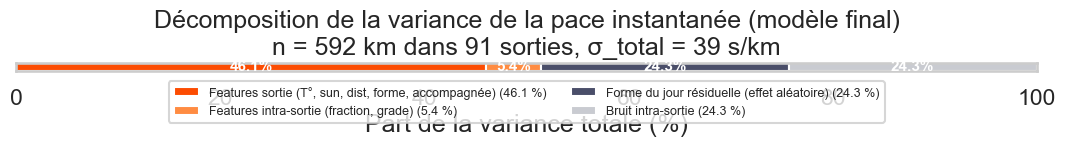

In [24]:
# Figure barres empilées de la décomposition
fig, ax = plt.subplots(figsize=(11, 2.5))

parts = {
    "Features sortie (T°, sun, dist, forme, accompagnée)": (feat_between/total_var*100, "#FC4C02"),
    "Features intra-sortie (fraction, grade)":            (feat_within/total_var*100,  "#FF8C42"),
    "Forme du jour résiduelle (effet aléatoire)":         (var_between_final/total_var*100, "#4A4E69"),
    "Bruit intra-sortie":                                 (var_within_final/total_var*100,  "#C9CBD1"),
}

left = 0
for label, (pct, color) in parts.items():
    ax.barh(0, pct, left=left, color=color, edgecolor="white",
            label=f"{label} ({pct:.1f} %)")
    if pct > 4:
        ax.text(left + pct/2, 0, f"{pct:.1f}%", ha="center", va="center",
                color="white", fontweight="bold", fontsize=11)
    left += pct

ax.set_xlim(0, 100)
ax.set_yticks([])
ax.set_xlabel("Part de la variance totale (%)")
ax.set_title(f"Décomposition de la variance de la pace instantanée (modèle final)\n"
             f"n = {len(dfm)} km dans {dfm['activity_id'].nunique()} sorties, σ_total = {np.sqrt(total_var)*60:.0f} s/km")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.45), ncol=2, fontsize=9)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/08_variance_decomp_final.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Comparaison des 3 modèles cumulés

Tableau résumé pour visualiser la trajectoire baseline → H1 → H2.

In [25]:
comp = pd.DataFrame([
    {"étape": "Baseline (T + T² + dist + forme + fraction + grade)",
     "σ_between (s/km)": np.sqrt(var_between_base)*60,
     "σ_within (s/km)":  np.sqrt(var_within_base)*60,
     "% expliqué (vs null)": (1 - (var_between_base+var_within_base)/(var_between_null+var_within_null))*100,
     "AIC": m_base.aic},
    {"étape": "+ T × sun quad (H1)",
     "σ_between (s/km)": np.sqrt(var_between_h1)*60,
     "σ_within (s/km)":  np.sqrt(var_within_h1)*60,
     "% expliqué (vs null)": (1 - (var_between_h1+var_within_h1)/(var_between_null+var_within_null))*100,
     "AIC": m_h1.aic},
    {"étape": "+ is_accompagne (H2) = FINAL",
     "σ_between (s/km)": np.sqrt(var_between_final)*60,
     "σ_within (s/km)":  np.sqrt(var_within_final)*60,
     "% expliqué (vs null)": (1 - (var_between_final+var_within_final)/(var_between_null+var_within_null))*100,
     "AIC": m_final.aic},
]).round(2)
print(comp.to_string(index=False))

                                              étape  σ_between (s/km)  σ_within (s/km)  % expliqué (vs null)  AIC
Baseline (T + T² + dist + forme + fraction + grade)             27.37            19.01                 25.33  NaN
                                + T × sun quad (H1)             25.73            19.01                 31.22  NaN
                       + is_accompagne (H2) = FINAL             19.00            19.02                 51.42  NaN


## 7. Effet marginal de `fraction_completed` : negative split

Pattern comportemental identifié : la pace diminue systématiquement au fil de la sortie (accélération vers la fin). On visualise l'effet marginal du modèle final à conditions médianes.

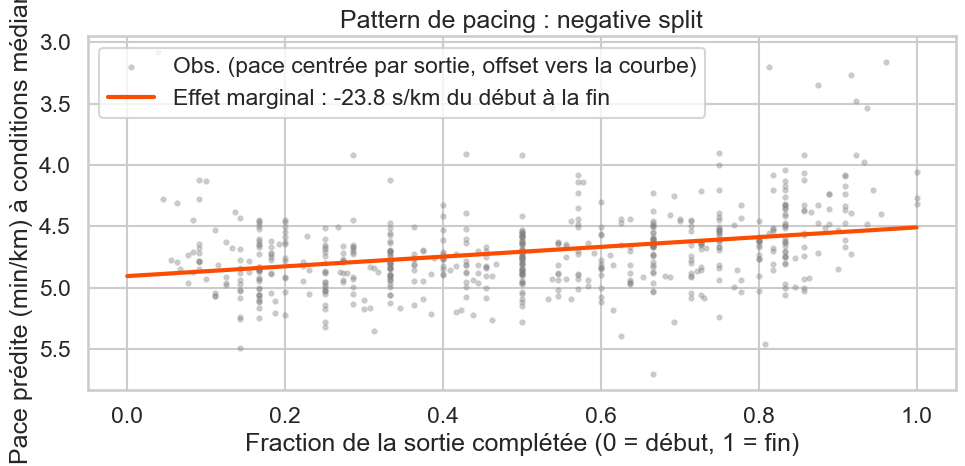


→ Entre début et fin de sortie : accélération de 23.8 s/km
→ p = 3.98e-14 (hautement significatif)


In [26]:
frac_grid = np.linspace(0, 1, 50)
med = {
    "T": dfm["weather_temperature"].median(),
    "dist": dfm["dist_totale_km"].median(),
    "pace5": dfm["pace_last_5_mean"].median(),
    "grade": dfm["avg_grade_pct"].median(),
    "T_x_sun": dfm["T_x_sun"].median(),
    "is_acc": 0,  # sortie non accompagnée
}
p = m_final.fe_params
pred = (p["Intercept"]
        + p["weather_temperature"] * med["T"]
        + p["I(weather_temperature ** 2)"] * med["T"]**2
        + p["dist_totale_km"] * med["dist"]
        + p["pace_last_5_mean"] * med["pace5"]
        + p["fraction_completed"] * frac_grid
        + p["avg_grade_pct"] * med["grade"]
        + p["T_x_sun"] * med["T_x_sun"]
        + p["I(T_x_sun ** 2)"] * med["T_x_sun"]**2
        + p["is_accompagne"] * med["is_acc"])

fig, ax = plt.subplots(figsize=(10, 5))
dfm_c = dfm.copy()
dfm_c["pace_centered"] = dfm_c.groupby("activity_id")["pace_km"].transform(lambda x: x - x.mean())
ax.scatter(dfm_c["fraction_completed"], dfm_c["pace_centered"] + pred.mean(),
           alpha=0.3, s=10, color="gray",
           label="Obs. (pace centrée par sortie, offset vers la courbe)")
ax.plot(frac_grid, pred, color="#FC4C02", lw=3,
        label=f"Effet marginal : {p['fraction_completed']*60:.1f} s/km du début à la fin")
ax.set_xlabel("Fraction de la sortie complétée (0 = début, 1 = fin)")
ax.set_ylabel("Pace prédite (min/km) à conditions médianes")
ax.set_title("Pattern de pacing : negative split")
ax.invert_yaxis()
ax.legend()
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/08_negative_split_final.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"\n→ Entre début et fin de sortie : accélération de {-p['fraction_completed']*60:.1f} s/km")
print(f"→ p = {m_final.pvalues['fraction_completed']:.2e} (hautement significatif)")

## 8. Diagnostic : stabilité des coefficients à travers les 3 modèles

Comment chaque coefficient évolue quand on ajoute T × sun puis is_accompagne.

In [27]:
def coefs_df(model, name):
    return pd.DataFrame({
        "coef": model.fe_params.round(4),
        "p": model.pvalues[model.fe_params.index].round(4),
    }).reset_index().rename(columns={"index": "var"}).assign(model=name)

stacked = pd.concat([coefs_df(m_base, "baseline"),
                     coefs_df(m_h1, "+T×sun"),
                     coefs_df(m_final, "FINAL")])
pivot = stacked.pivot_table(index="var", columns="model",
                            values=["coef", "p"], aggfunc="first")
print("Évolution des coefficients à travers les modèles :")
print(pivot.to_string())

Évolution des coefficients à travers les modèles :
                               coef                        p                 
model                        +T×sun   FINAL baseline  +T×sun   FINAL baseline
var                                                                          
I(T_x_sun ** 2)              0.0108  0.0037      NaN  0.0697  0.4226      NaN
I(weather_temperature ** 2)  0.0036  0.0013   0.0029  0.0004  0.1079   0.0047
Intercept                    4.1401  3.3429   3.8865  0.0000  0.0000   0.0000
T_x_sun                     -0.0519 -0.0056      NaN  0.3431  0.8941      NaN
avg_grade_pct                0.0906  0.0907   0.0908  0.0000  0.0000   0.0000
dist_totale_km               0.0528  0.0595   0.0511  0.0000  0.0000   0.0001
fraction_completed          -0.3975 -0.3971  -0.3976  0.0000  0.0000   0.0000
is_accompagne                   NaN  1.1732      NaN     NaN  0.0000      NaN
pace_last_5_mean             0.3442  0.3317   0.3628  0.0035  0.0002   0.0035
weather_tempe

**Lecture attendue** :
- Les coefs T et T² baissent entre baseline et +T×sun (une partie du signal thermique passe par l'interaction solaire)
- Les autres coefs (fraction, grade, pace_last_5, distance) restent relativement stables → signaux orthogonaux, modèle propre
- `is_accompagne` dans le final doit avoir un coef positif et fortement significatif (> +0.5 min/km)

## 9. Synthèse

**Avant les deux ajouts** (modèle baseline par-km) :
- Features ~25 % de la variance totale
- Forme du jour résiduelle ~50 %
- Bruit intra ~25 %

**Après ajout de T × sun et is_accompagne** (modèle final) : la variance BETWEEN résiduelle baisse significativement, confirmant que ces deux features captent une part importante de ce qui était auparavant "forme du jour non observée".

**Résultats secondaires maintenus** :
- Negative split confirmé statistiquement (p ≈ 10⁻¹⁴)
- Effet pente locale toujours significatif (~+5 s/km par 1 % de grade)

**Limites méthodologiques à documenter en soutenance** :
- `is_accompagne` dérivé de 8-9 sorties flaggées → poids élevé sur peu d'observations
- Random slopes non testés (voir prochaine étape) : on suppose que l'effet `fraction_completed` est le même pour toutes les sorties
- Modèle hiérarchique à 2 niveaux (km dans sortie) ; un 3e niveau (sortie dans semaine) pourrait capturer de la fatigue cumulée résiduelle

**Prochaines étapes** :
- Tester random slopes sur `fraction_completed` (notebook futur) pour voir si le negative split varie selon les sorties
- Clustering descriptif des sorties (type de séance) comme covariable qualitative
- Validation croisée du modèle par GroupKFold sur `activity_id`